# Exploración inicial del historial

`00_KIT/historial/historial.csv` junta los casos históricos de admisión.
Esta notebook los describe antes de clasificarlos: tamaño, tipos, faltantes
y cómo se cruzan las variables que más pesan en el circuito de guardia.


## Carga

El archivo se busca desde la raíz del repositorio o desde `10_CURADO`.
Las celdas vacías del CSV quedan como nulos.


In [4]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 140)

plt.rcParams.update({
    "figure.figsize": (10, 4),
    "axes.grid": True,
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def ruta_historial() -> Path:
    candidatos = [
        Path("historial") / "historial.csv",
        Path("..") / "00_KIT" / "historial" / "historial.csv",
    ]
    for ruta in candidatos:
        if ruta.exists():
            return ruta
    raise FileNotFoundError(
        "No encontré historial.csv. Ejecutá el notebook desde la raíz del repo o desde 10_CURADO."
    )


RUTA = ruta_historial()
df = pd.read_csv(RUTA, encoding="utf-8")
df["fecha"] = pd.to_datetime(df["fecha"])

print(RUTA.resolve())
print(f"{len(df):,} filas × {df.shape[1]} columnas")


C:\Users\disar\OneDrive\Escritorio\facultad\3_año\segundo_cuat\Generativa\TP_final_generativa\TPFinal\historial\historial.csv
2,000 filas × 28 columnas


## Tamaño, tipos y muestra

Cada fila es una atención. `id` y `fecha` no se repiten.


In [5]:
print("filas duplicadas:", int(df.duplicated().sum()))
print("ids duplicados:", int(df["id"].duplicated().sum()))
print("desde", df["fecha"].min(), "hasta", df["fecha"].max())

resumen = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "pct_nulos": (df.isna().mean() * 100).round(1),
    "unicos": [df[c].nunique(dropna=True) for c in df.columns],
})
resumen


filas duplicadas: 0
ids duplicados: 0
desde 2026-03-01 00:45:00 hasta 2026-05-05 11:22:00


,tipo,nulos,pct_nulos,unicos
id,str,0,0.0,2000
fecha,datetime64[us],0,0.0,2000
operador,str,0,0.0,20
edad,int64,0,0.0,71
nivel,int64,0,0.0,5
motivo,str,0,0.0,9
nota_enfermeria,str,0,0.0,225
sospecha_sepsis,str,0,0.0,4
llegada,str,0,0.0,2
documento_tipo,str,788,39.4,3


In [21]:
df.head(8)


,id,fecha,operador,edad,nivel,motivo,nota_enfermeria,sospecha_sepsis,llegada,documento_tipo,documento_numero,credenciales,puede_responder,acompanante,lesion_trabajo,cobertura_declarada,art_declarada,entidad_verificada,numero_verificado,respuesta_verificacion,registro,numero_documento,box_antes_del_registro,circuito,plazo_circuito_min,cobertura,entidad_a_notificar,aviso_al_voluntariado
0,H-0001,2026-03-01 00:45:00,OP-08,57,2,sospecha de sepsis,Fiebre de 39 °C y escalofríos desde ayer; presión baja y somnolencia.,con signos de shock,por sus propios medios,DNI,41.302.257,NaN,sí,NaN,no,Obra Social Tilcara (obra social) 30-966417-1,NaN,Obra Social Tilcara,30-966417-1,inactiva,definitivo,41.302.257,sí,codigo_sepsis,15.0,sin_cobertura,NaN,no
1,H-0002,2026-03-01 01:10:00,OP-12,63,1,sospecha de sepsis,Fiebre y ardor al orinar desde hace dos días; signos vitales estables.,"posible, sin signos de shock",por sus propios medios,DNI,14.094.028,NaN,no,NaN,no,NaN,NaN,NaN,NaN,NaN,definitivo,14.094.028,sí,codigo_sepsis,60.0,sin_cobertura,NaN,no
2,H-0003,2026-03-01 01:23:00,OP-13,48,2,dolor abdominal,"Dolor abdominal intenso desde hace 3 horas, con vómitos.",no,por sus propios medios,DNI,23.260.360,Obra Social Bermejo (obra social) 18-876602-7,sí,NaN,no,NaN,NaN,Obra Social Bermejo,18-876602-7,inactiva,definitivo,23.260.360,sí,ninguno,NaN,sin_cobertura,Obra Social Bermejo,no
3,H-0004,2026-03-01 02:18:00,OP-15,51,2,dolor torácico,Dolor en el centro del pecho que empezó hace 27 minutos mientras caminaba.,no,por sus propios medios,DNI,20.385.467,NaN,no,NaN,no,NaN,NaN,NaN,NaN,NaN,definitivo,20.385.467,sí,ecg,10.0,sin_cobertura,NaN,no
4,H-0005,2026-03-01 03:01:00,OP-04,35,2,dolor torácico,"Se lesionó en el trayecto entre su casa y el trabajo: dolor en el pecho desde hace 39 minutos, después de ...",no,por sus propios medios,cédula,28.281.926,NaN,sí,NaN,en el trayecto,ninguna,Pampa Laboral ART CUIL 23-28281926-3,Pampa Laboral ART,23-28281926-3,activa,provisorio,28.281.926,sí,ecg,10.0,art,Pampa Laboral ART,sí
5,H-0006,2026-03-01 04:15:00,OP-17,48,1,palpitaciones,"Palpitaciones desde hace una hora, con mareo.",no,en ambulancia,NaN,NaN,NaN,no,NaN,no,NaN,NaN,NaN,NaN,NaN,provisorio,NaN,sí,ninguno,NaN,sin_cobertura,NaN,sí
6,H-0007,2026-03-01 05:02:00,OP-13,55,4,fiebre y tos,"Fiebre de 38,5 °C y tos con flema desde hace cuatro días.",no,por sus propios medios,cédula,43.801.741,NaN,sí,NaN,no,ninguna,NaN,NaN,NaN,NaN,definitivo,43.801.741,no,ninguno,NaN,sin_cobertura,NaN,no
7,H-0008,2026-03-01 05:07:00,OP-02,68,2,dolor torácico,"Dolor opresivo en el pecho desde hace 25 minutos, que se le va al brazo izquierdo.",no,por sus propios medios,NaN,NaN,Obra Social Tilcara (obra social) 78-188951-0,sí,su hermana Laura,no,NaN,NaN,Obra Social Tilcara,78-188951-0,inactiva,provisorio,NaN,sí,ecg,10.0,sin_cobertura,NaN,no


## Análisis univariado

Cada variable se mira sola, en el orden del archivo. En todas se marca cuántos nulos hay.

- **Numérica:** distribución. Histograma si hay muchos valores; barras si son pocos. El vacío entra en las barras.
- **Fecha:** casos por día y por hora.
- **Categórica:** hasta 30 valores distintos. Distribución de clases, con el vacío como una clase más.
- **Texto:** los textos que más se repiten. Si ninguno se repite, ejemplos.
- **Objeto con demasiados distintos** para tratarlo como categoría: los valores que más se repiten y ejemplos del resto. Si ninguno se repite, solo ejemplos.


### `id`

muchos valores · `object` · 2000 distintos · **nulos: 0 (0.0%)**

Ningún valor se repite (2000 distintos entre 2000 no nulos). Algunos ejemplos:


,ejemplo
0,H-0001
1,H-0002
2,H-0003
3,H-0004
4,H-0005
5,H-0006


### `fecha`

fecha · `datetime64[ns]` · 2000 distintos · **nulos: 0 (0.0%)**

desde 2026-03-01 00:45:00 hasta 2026-05-05 11:22:00


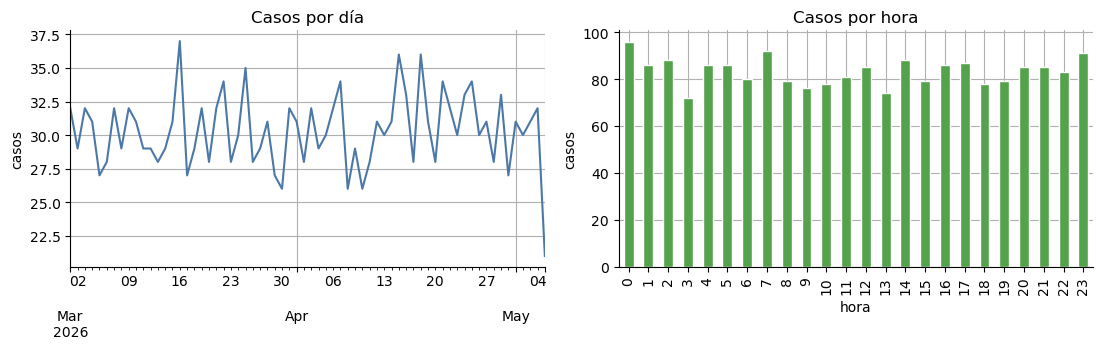

### `operador`

categórica · `object` · 20 distintos · **nulos: 0 (0.0%)**

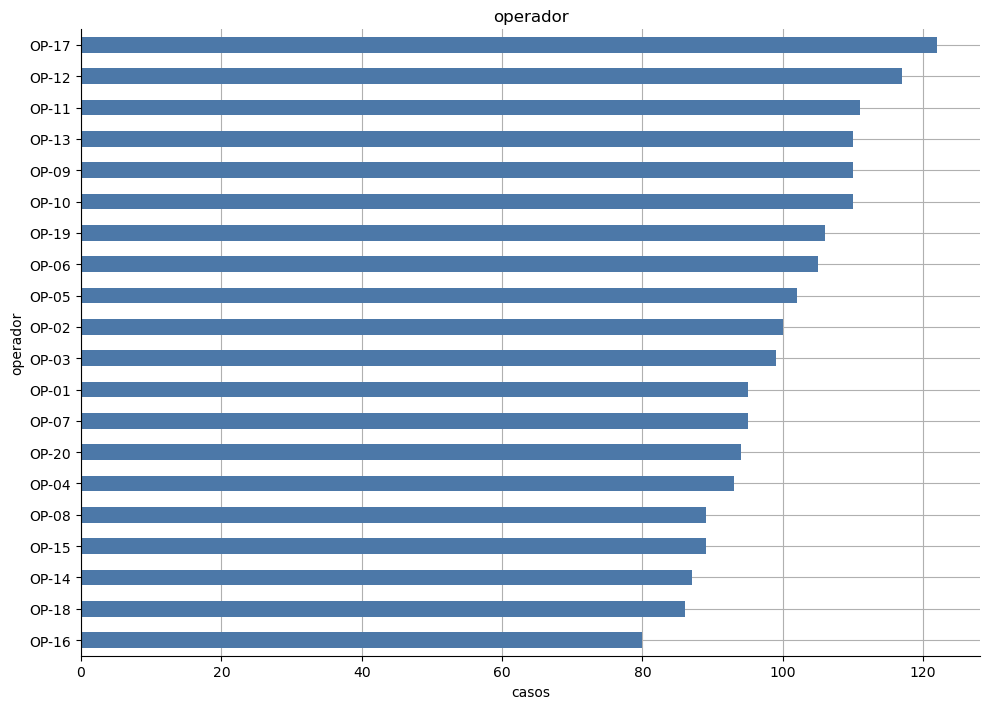

,casos,pct
operador,,
OP-17,122,6.1
OP-12,117,5.9
OP-11,111,5.6
OP-13,110,5.5
OP-09,110,5.5
OP-10,110,5.5
OP-19,106,5.3
OP-06,105,5.2
OP-05,102,5.1


### `edad`

numérica · `int64` · 71 distintos · **nulos: 0 (0.0%)**

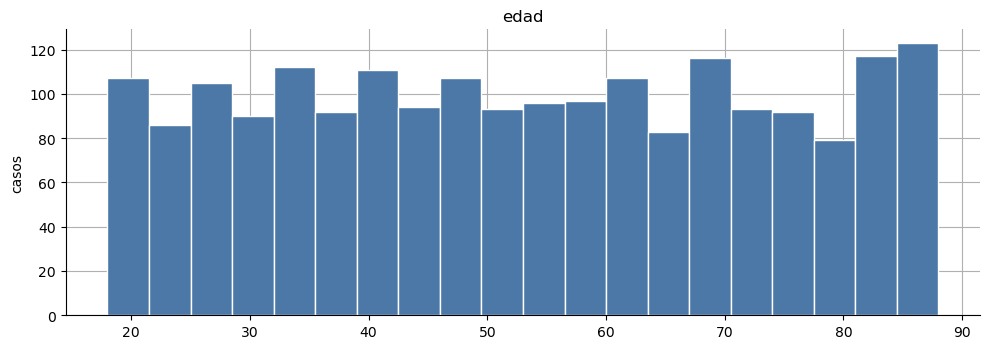

,count,mean,std,min,25%,50%,75%,max
edad,2000.0,53.1,20.5,18.0,35.8,53.0,71.0,88.0


### `nivel`

numérica · `int64` · 5 distintos · **nulos: 0 (0.0%)**

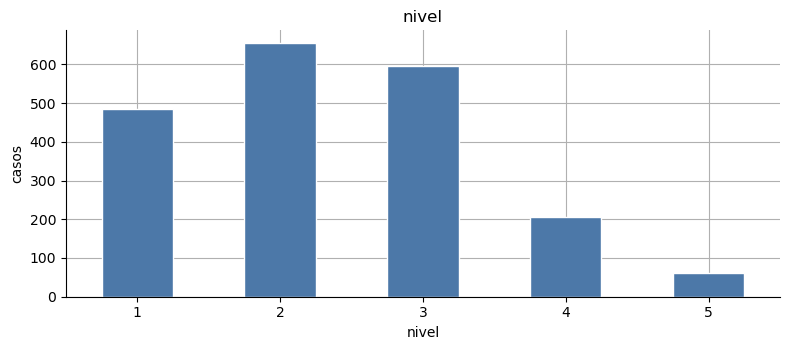

,casos,pct
nivel,,
1,485,24.2
2,655,32.8
3,595,29.8
4,205,10.2
5,60,3.0


### `motivo`

categórica · `object` · 9 distintos · **nulos: 0 (0.0%)**

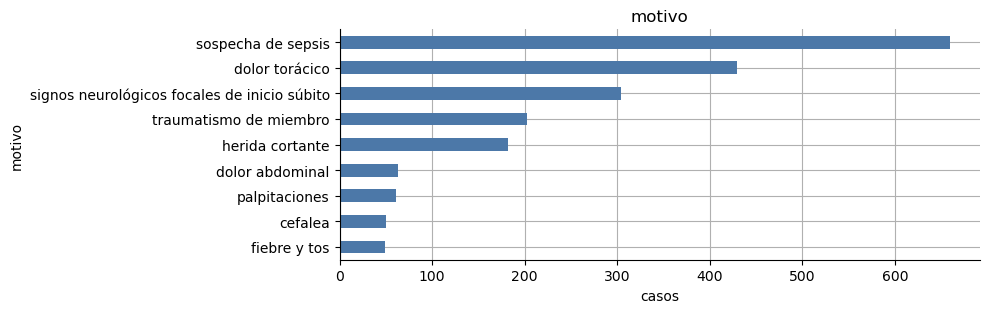

,casos,pct
motivo,,
sospecha de sepsis,659,33.0
dolor torácico,429,21.4
signos neurológicos focales de inicio súbito,304,15.2
traumatismo de miembro,203,10.2
herida cortante,182,9.1
dolor abdominal,63,3.2
palpitaciones,61,3.0
cefalea,50,2.5
fiebre y tos,49,2.4


### `nota_enfermeria`

texto · `object` · 225 distintos · **nulos: 0 (0.0%)**

Además hay 178 valores más que también se repiten y 32 que aparecen una sola vez.


,casos,pct
nota_enfermeria,,
Fiebre de 39 °C y escalofríos desde ayer; presión baja y somnolencia.,182,9.1
Fiebre alta y confusión desde la mañana; frecuencia cardíaca alta.,174,8.7
"Fiebre de 38,4 °C desde anoche y malestar general.",163,8.2
Fiebre y ardor al orinar desde hace dos días; signos vitales estables.,140,7.0
Se lesionó trabajando: se cayó de una escalera y le duele mucho la muñeca.,71,3.6
"Se torció el tobillo; dolor e hinchazón, puede apoyar el pie.",70,3.5
Se lesionó trabajando: se cortó el antebrazo con una chapa; sangrado controlado.,64,3.2
Se lesionó en el trayecto entre su casa y el trabajo: se cayó de una escalera y le duele mucho la muñeca.,62,3.1
Se lesionó en el trayecto entre su casa y el trabajo: se cortó el antebrazo con una chapa; sangrado controlado.,61,3.0


### `sospecha_sepsis`

categórica · `object` · 4 distintos · **nulos: 0 (0.0%)**

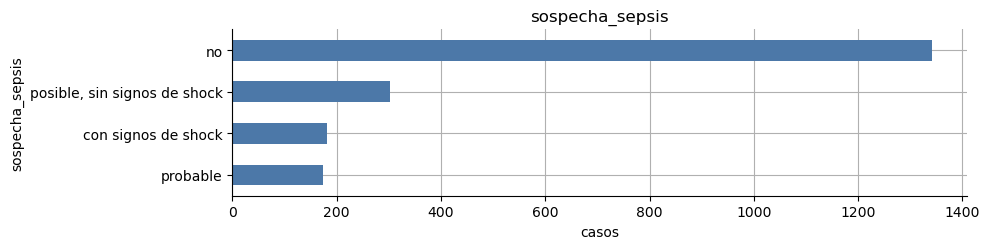

,casos,pct
sospecha_sepsis,,
no,1341,67.0
"posible, sin signos de shock",303,15.2
con signos de shock,182,9.1
probable,174,8.7


### `llegada`

categórica · `object` · 2 distintos · **nulos: 0 (0.0%)**

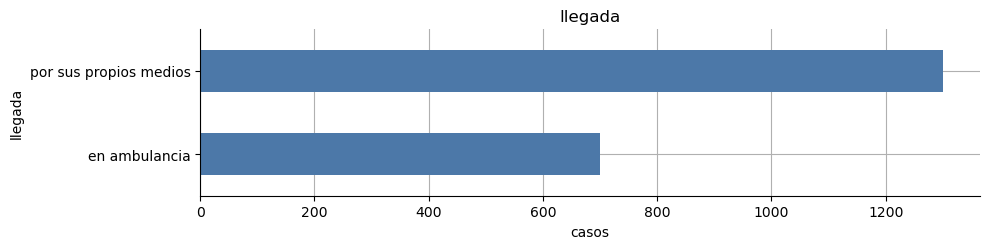

,casos,pct
llegada,,
por sus propios medios,1300,65.0
en ambulancia,700,35.0


### `documento_tipo`

categórica · `object` · 3 distintos · **nulos: 788 (39.4%)**

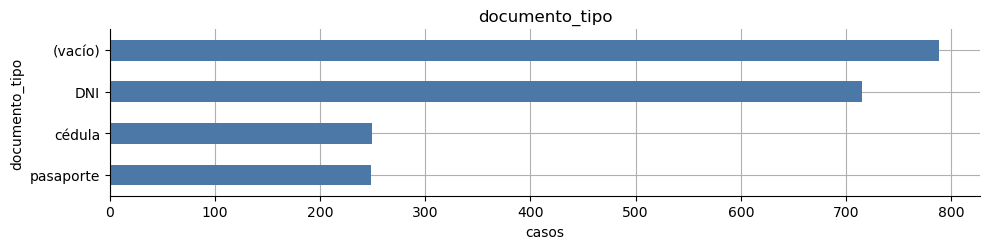

,casos,pct
documento_tipo,,
(vacío),788,39.4
DNI,715,35.8
cédula,249,12.4
pasaporte,248,12.4


### `documento_numero`

muchos valores · `object` · 1212 distintos · **nulos: 788 (39.4%)**

Ningún valor se repite (1212 distintos entre 1212 no nulos). Algunos ejemplos:


,ejemplo
0,41.302.257
1,14.094.028
2,23.260.360
3,20.385.467
4,28.281.926
5,43.801.741


### `credenciales`

muchos valores · `object` · 778 distintos · **nulos: 1,222 (61.1%)**

Ningún valor se repite (778 distintos entre 778 no nulos). Algunos ejemplos:


,ejemplo
0,Obra Social Bermejo (obra social) 18-876602-7
1,Obra Social Tilcara (obra social) 78-188951-0
2,Prepaga Sierra (prepaga) 148517/05
3,Obra Social Fluvial (obra social) 25-448977-7; Prepaga Cumbre (prepaga) 967186/04
4,Obra Social Fluvial (obra social) 14-250918-1; Prepaga Sierra (prepaga) 296379/03
5,Obra Social Tilcara (obra social) 46-528101-6


### `puede_responder`

categórica · `object` · 2 distintos · **nulos: 0 (0.0%)**

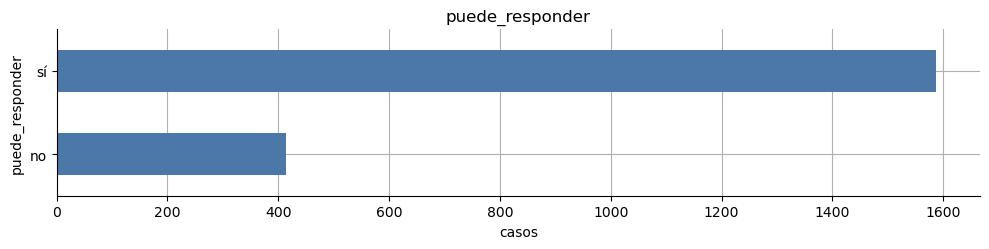

,casos,pct
puede_responder,,
sí,1587,79.4
no,413,20.6


### `acompanante`

categórica · `object` · 24 distintos · **nulos: 1,155 (57.8%)**

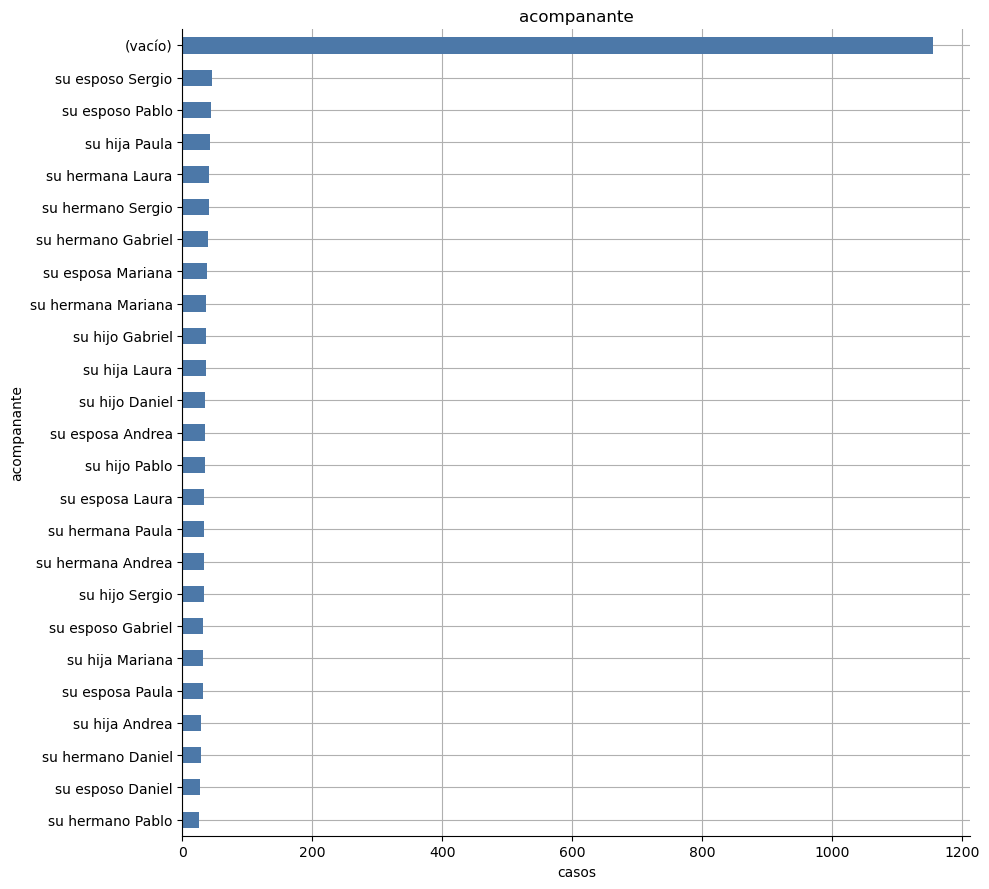

,casos,pct
acompanante,,
(vacío),1155,57.8
su esposo Sergio,45,2.2
su esposo Pablo,44,2.2
su hija Paula,42,2.1
su hermana Laura,41,2.1
su hermano Sergio,41,2.1
su hermano Gabriel,40,2.0
su esposa Mariana,38,1.9
su hermana Mariana,37,1.8


### `lesion_trabajo`

categórica · `object` · 3 distintos · **nulos: 0 (0.0%)**

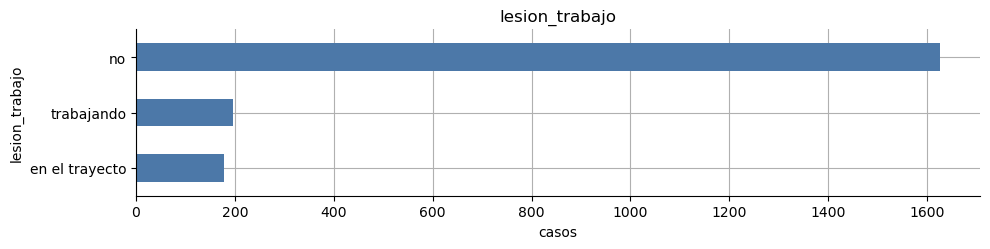

,casos,pct
lesion_trabajo,,
no,1626,81.3
trabajando,197,9.8
en el trayecto,177,8.8


### `cobertura_declarada`

muchos valores · `object` · 714 distintos · **nulos: 969 (48.4%)**

Además hay 713 que aparecen una sola vez.


,casos,pct
cobertura_declarada,,
ninguna,318,15.9


Algunos ejemplos de los que aparecen una sola vez:


,ejemplo
0,Obra Social Tilcara (obra social) 30-966417-1
1,Prepaga Litoral (prepaga) 706755/08
2,Obra Social Bermejo (obra social) 61-692534-8
3,Obra Social Fluvial (obra social) 55-486187-4
4,Obra Social Bermejo (obra social) 14-548878-0
5,Obra Social Tilcara (obra social) 41-568851-8


### `art_declarada`

muchos valores · `object` · 374 distintos · **nulos: 1,626 (81.3%)**

Ningún valor se repite (374 distintos entre 374 no nulos). Algunos ejemplos:


,ejemplo
0,Pampa Laboral ART CUIL 23-28281926-3
1,Andina ART CUIL 23-27628764-2
2,Pampa Laboral ART CUIL 23-21171162-0
3,Riesgos del Sur ART CUIL 27-16412991-6
4,Andina ART CUIL 20-10946350-1
5,Andina ART CUIL 27-45107039-7


### `entidad_verificada`

categórica · `object` · 9 distintos · **nulos: 413 (20.6%)**

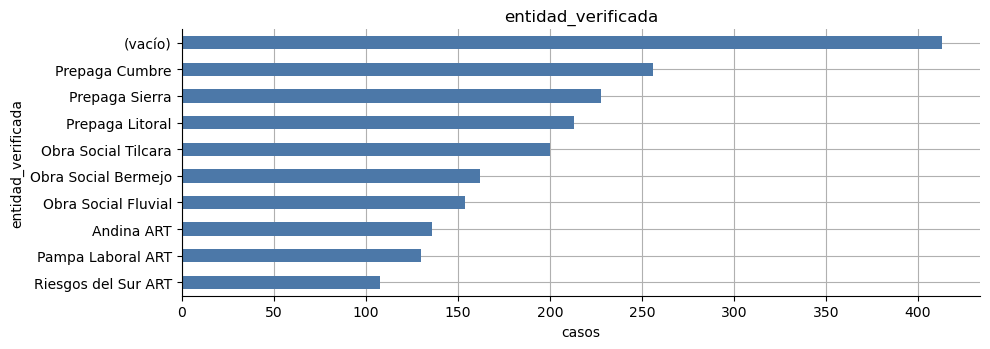

,casos,pct
entidad_verificada,,
(vacío),413,20.6
Prepaga Cumbre,256,12.8
Prepaga Sierra,228,11.4
Prepaga Litoral,213,10.6
Obra Social Tilcara,200,10.0
Obra Social Bermejo,162,8.1
Obra Social Fluvial,154,7.7
Andina ART,136,6.8
Pampa Laboral ART,130,6.5


### `numero_verificado`

muchos valores · `object` · 1587 distintos · **nulos: 413 (20.6%)**

Ningún valor se repite (1587 distintos entre 1587 no nulos). Algunos ejemplos:


,ejemplo
0,30-966417-1
1,18-876602-7
2,23-28281926-3
3,78-188951-0
4,23-27628764-2
5,967186/04


### `respuesta_verificacion`

categórica · `object` · 2 distintos · **nulos: 413 (20.6%)**

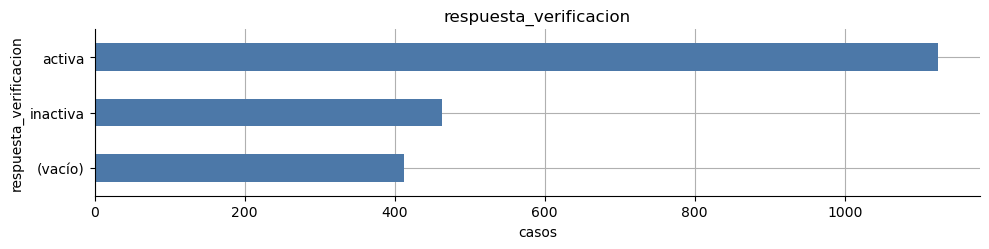

,casos,pct
respuesta_verificacion,,
activa,1124,56.2
inactiva,463,23.2
(vacío),413,20.6


### `registro`

categórica · `object` · 2 distintos · **nulos: 0 (0.0%)**

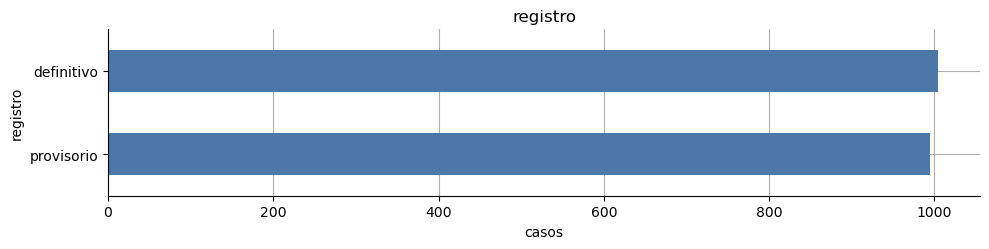

,casos,pct
registro,,
definitivo,1005,50.2
provisorio,995,49.8


### `numero_documento`

muchos valores · `object` · 1212 distintos · **nulos: 788 (39.4%)**

Ningún valor se repite (1212 distintos entre 1212 no nulos). Algunos ejemplos:


,ejemplo
0,41.302.257
1,14.094.028
2,23.260.360
3,20.385.467
4,28.281.926
5,43.801.741


### `box_antes_del_registro`

categórica · `object` · 2 distintos · **nulos: 0 (0.0%)**

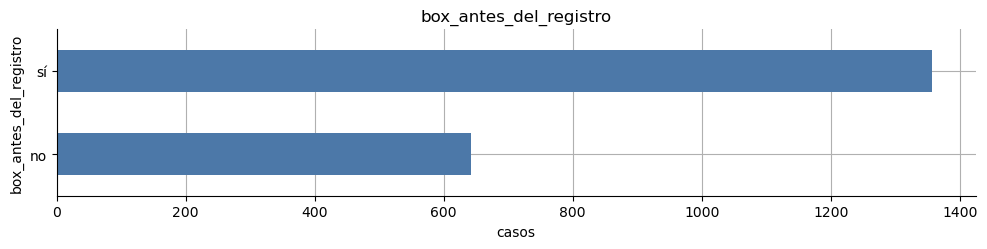

,casos,pct
box_antes_del_registro,,
sí,1357,67.8
no,643,32.2


### `circuito`

categórica · `object` · 4 distintos · **nulos: 0 (0.0%)**

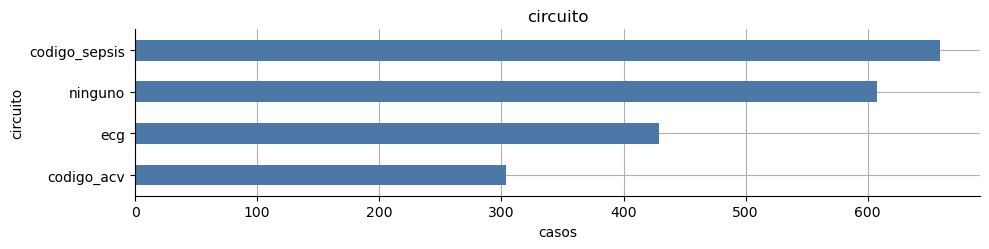

,casos,pct
circuito,,
codigo_sepsis,659,33.0
ninguno,608,30.4
ecg,429,21.4
codigo_acv,304,15.2


### `plazo_circuito_min`

numérica · `float64` · 5 distintos · **nulos: 608 (30.4%)**

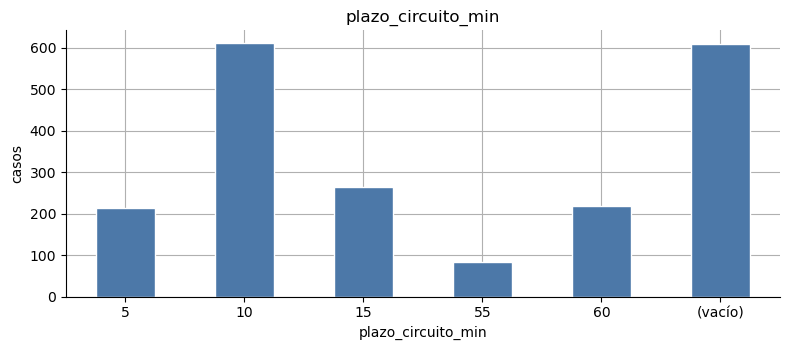

,casos,pct
plazo_circuito_min,,
5,214,10.7
10,611,30.6
15,264,13.2
55,84,4.2
60,219,11.0
(vacío),608,30.4


### `cobertura`

categórica · `object` · 4 distintos · **nulos: 0 (0.0%)**

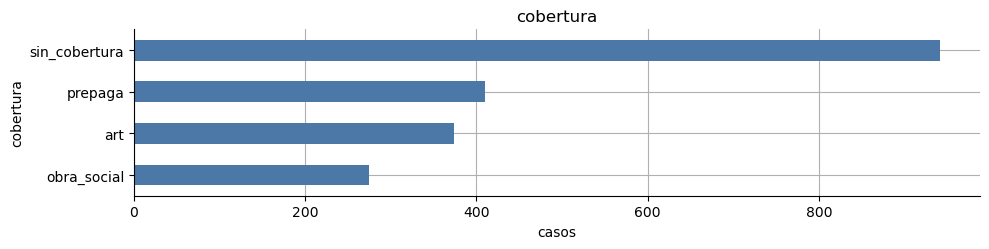

,casos,pct
cobertura,,
sin_cobertura,941,47.0
prepaga,410,20.5
art,374,18.7
obra_social,275,13.8


### `entidad_a_notificar`

categórica · `object` · 9 distintos · **nulos: 828 (41.4%)**

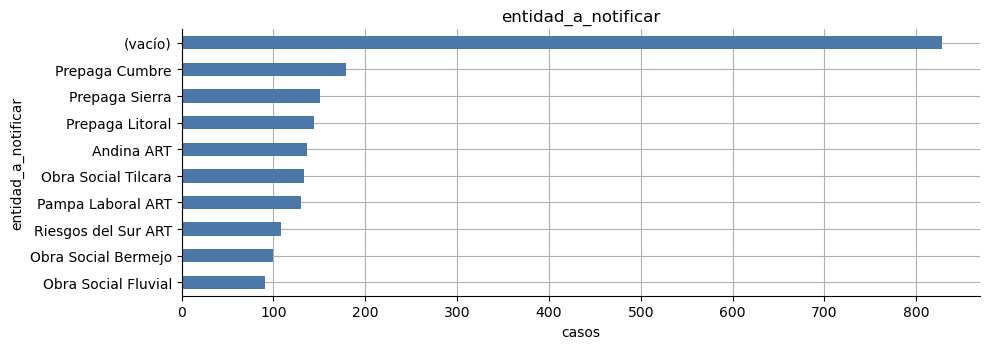

,casos,pct
entidad_a_notificar,,
(vacío),828,41.4
Prepaga Cumbre,179,9.0
Prepaga Sierra,151,7.6
Prepaga Litoral,144,7.2
Andina ART,136,6.8
Obra Social Tilcara,133,6.6
Pampa Laboral ART,130,6.5
Riesgos del Sur ART,108,5.4
Obra Social Bermejo,100,5.0


### `aviso_al_voluntariado`

categórica · `object` · 2 distintos · **nulos: 0 (0.0%)**

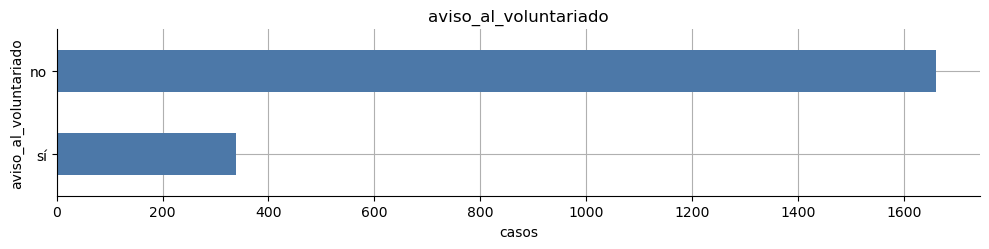

,casos,pct
aviso_al_voluntariado,,
no,1661,83.0
sí,339,17.0


In [22]:
from IPython.display import Markdown

MAX_CLASES = 30


def etiqueta(valor):
    if pd.isna(valor):
        return "(vacío)"
    if isinstance(valor, str):
        return valor
    try:
        numero = float(valor)
    except (TypeError, ValueError):
        return valor
    if numero.is_integer():
        return str(int(numero))
    return valor


def tabla_clases(serie: pd.Series, por_valor: bool) -> pd.DataFrame:
    conteos = serie.value_counts(dropna=False)
    if por_valor:
        conteos = conteos.sort_index(na_position="last")
    tabla = conteos.rename("casos").to_frame()
    tabla["pct"] = (tabla["casos"] / len(serie) * 100).round(1)
    tabla.index = [etiqueta(v) for v in tabla.index]
    tabla.index.name = serie.name
    return tabla


def barras(tabla: pd.DataFrame, titulo: str, horizontal: bool) -> None:
    if horizontal:
        alto = max(2.6, 0.36 * len(tabla))
        fig, ax = plt.subplots(figsize=(10, alto))
        tabla["casos"].iloc[::-1].plot.barh(ax=ax, color="#4C78A8")
        ax.set_xlabel("casos")
    else:
        fig, ax = plt.subplots(figsize=(8, 3.6))
        tabla["casos"].plot.bar(ax=ax, color="#4C78A8", edgecolor="white")
        ax.set_ylabel("casos")
        ax.tick_params(axis="x", rotation=0)
    ax.set_title(titulo)
    plt.tight_layout()
    plt.show()


def es_texto(serie: pd.Series) -> bool:
    textos = serie.dropna().astype(str)
    if textos.empty:
        return False
    mediana = float(textos.str.len().median())
    proporcion = serie.nunique(dropna=True) / len(textos)
    return mediana >= 60 and proporcion < 0.5


def encabezado(columna: str, serie: pd.Series, clase: str) -> None:
    nulos = int(serie.isna().sum())
    pct = nulos / len(serie) * 100
    distintos = int(serie.nunique(dropna=True))
    display(Markdown(
        f"### `{columna}`\n\n"
        f"{clase} · `{serie.dtype}` · {distintos} distintos · "
        f"**nulos: {nulos:,} ({pct:.1f}%)**"
    ))


def mostrar_frecuentes(serie: pd.Series, ejemplos: bool = False) -> None:
    ranking = serie.value_counts(dropna=True)
    repetidos = ranking[ranking > 1]
    if repetidos.empty:
        print(
            "Ningún valor se repite "
            f"({int(ranking.shape[0])} distintos entre {int(serie.notna().sum())} no nulos). "
            "Algunos ejemplos:"
        )
        display(
            serie.dropna()
            .drop_duplicates()
            .head(6)
            .to_frame("ejemplo")
            .reset_index(drop=True)
        )
        return

    tope = 15
    tabla = repetidos.head(tope).rename("casos").to_frame()
    tabla["pct"] = (tabla["casos"] / len(serie) * 100).round(1)
    tabla.index.name = serie.name
    fuera = int(repetidos.shape[0] - len(tabla))
    una_vez = int((ranking == 1).sum())
    partes = []
    if fuera:
        partes.append(f"{fuera:,} valores más que también se repiten")
    if una_vez:
        partes.append(f"{una_vez:,} que aparecen una sola vez")
    if partes:
        print("Además hay " + " y ".join(partes) + ".")
    display(tabla)
    if ejemplos and una_vez:
        unicos = ranking[ranking == 1].index
        muestra = (
            serie.dropna()
            .loc[lambda s: s.isin(unicos)]
            .drop_duplicates()
            .head(6)
            .to_frame("ejemplo")
            .reset_index(drop=True)
        )
        print("Algunos ejemplos de los que aparecen una sola vez:")
        display(muestra)


def analizar(columna: str) -> None:
    serie = df[columna]
    if pd.api.types.is_numeric_dtype(serie):
        clase = "numérica"
    elif pd.api.types.is_datetime64_any_dtype(serie):
        clase = "fecha"
    elif int(serie.nunique(dropna=True)) <= MAX_CLASES:
        clase = "categórica"
    elif es_texto(serie):
        clase = "texto"
    else:
        clase = "muchos valores"
    encabezado(columna, serie, clase)

    if int(serie.notna().sum()) == 0:
        return

    if clase == "numérica":
        if int(serie.nunique(dropna=True)) <= 15:
            tabla = tabla_clases(serie, por_valor=True)
            barras(tabla, columna, horizontal=False)
            display(tabla)
            return
        observados = serie.dropna()
        fig, ax = plt.subplots(figsize=(10, 3.6))
        observados.plot.hist(bins=20, ax=ax, color="#4C78A8", edgecolor="white")
        ax.set_title(columna)
        ax.set_xlabel("")
        ax.set_ylabel("casos")
        plt.tight_layout()
        plt.show()
        resumen_num = observados.describe().round(1).to_frame().T
        resumen_num.index = [columna]
        display(resumen_num)
        return

    if clase == "fecha":
        print("desde", serie.min(), "hasta", serie.max())
        fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
        por_dia = (
            pd.Series(1, index=pd.DatetimeIndex(serie.dropna()))
            .resample("D")
            .sum()
        )
        por_dia.plot(ax=axes[0], color="#4C78A8")
        axes[0].set_title("Casos por día")
        axes[0].set_xlabel("")
        axes[0].set_ylabel("casos")
        serie.dropna().dt.hour.value_counts().sort_index().plot.bar(
            ax=axes[1], color="#54A24B", edgecolor="white"
        )
        axes[1].set_title("Casos por hora")
        axes[1].set_xlabel("hora")
        axes[1].set_ylabel("casos")
        plt.tight_layout()
        plt.show()
        return

    if clase == "categórica":
        tabla = tabla_clases(serie, por_valor=False)
        barras(tabla, columna, horizontal=True)
        display(tabla)
        return

    mostrar_frecuentes(serie, ejemplos=clase == "muchos valores")


for columna in df.columns:
    analizar(columna)


## Relaciones que ya se ven

Tres cruces salen casi deterministas y conviene tenerlos a la vista antes de curar:

- el circuito depende del motivo;
- el plazo solo existe si hay circuito;
- la lesión laboral cierra siempre como ART, y el registro definitivo exige documento.


In [23]:
pd.crosstab(df["motivo"], df["circuito"], margins=True)


circuito,codigo_acv,codigo_sepsis,ecg,ninguno,All
motivo,,,,,
cefalea,0,0,0,50,50
dolor abdominal,0,0,0,63,63
dolor torácico,0,0,429,0,429
fiebre y tos,0,0,0,49,49
herida cortante,0,0,0,182,182
palpitaciones,0,0,0,61,61
signos neurológicos focales de inicio súbito,304,0,0,0,304
sospecha de sepsis,0,659,0,0,659
traumatismo de miembro,0,0,0,203,203


In [24]:
pd.crosstab(
    df["circuito"],
    df["plazo_circuito_min"].map(lambda v: "sin plazo" if pd.isna(v) else f"{int(v)} min"),
    margins=True,
)


plazo_circuito_min,10 min,15 min,5 min,55 min,60 min,sin plazo,All
circuito,,,,,,,
codigo_acv,211,0,93,0,0,0,304
codigo_sepsis,92,264,0,84,219,0,659
ecg,308,0,121,0,0,0,429
ninguno,0,0,0,0,0,608,608
All,611,264,214,84,219,608,2000


In [25]:
pd.crosstab(df["lesion_trabajo"], df["cobertura"], margins=True)


cobertura,art,obra_social,prepaga,sin_cobertura,All
lesion_trabajo,,,,,
en el trayecto,177,0,0,0,177
no,0,275,410,941,1626
trabajando,197,0,0,0,197
All,374,275,410,941,2000


In [26]:
tiene_documento = df["documento_numero"].notna().map({True: "con documento", False: "sin documento"})
pd.crosstab(df["registro"], tiene_documento, margins=True)


documento_numero,con documento,sin documento,All
registro,,,
definitivo,1005,0,1005
provisorio,207,788,995
All,1212,788,2000


In [27]:
es_sepsis = df["motivo"].eq("sospecha de sepsis").map({True: "sospecha de sepsis", False: "otro motivo"})
pd.crosstab(es_sepsis, df["sospecha_sepsis"], margins=True)


sospecha_sepsis,con signos de shock,no,"posible, sin signos de shock",probable,All
motivo,,,,,
otro motivo,0,1341,0,0,1341
sospecha de sepsis,182,0,303,174,659
All,182,1341,303,174,2000


In [28]:
tiene_credencial = df["credenciales"].notna()
tiene_cobertura = df["cobertura_declarada"].notna()

cruce = pd.crosstab(
    tiene_credencial.map({True: "con valor", False: "vacía"}).rename("credenciales"),
    tiene_cobertura.map({True: "con valor", False: "vacía"}).rename("cobertura_declarada"),
    margins=True,
)
display(cruce)

pares = pd.concat([
    df.loc[tiene_credencial & ~tiene_cobertura, ["id", "credenciales", "cobertura_declarada"]].head(8),
    df.loc[~tiene_credencial & tiene_cobertura, ["id", "credenciales", "cobertura_declarada"]].head(8),
    df.loc[~tiene_credencial & ~tiene_cobertura, ["id", "credenciales", "cobertura_declarada"]].head(4),
])
display(pares)



cobertura_declarada,con valor,vacía,All
credenciales,,,
con valor,0,778,778
vacía,1031,191,1222
All,1031,969,2000


,id,credenciales,cobertura_declarada
2,H-0003,Obra Social Bermejo (obra social) 18-876602-7,NaN
7,H-0008,Obra Social Tilcara (obra social) 78-188951-0,NaN
8,H-0009,Prepaga Sierra (prepaga) 148517/05,NaN
9,H-0010,Obra Social Fluvial (obra social) 25-448977-7; Prepaga Cumbre (prepaga) 967186/04,NaN
10,H-0011,Obra Social Fluvial (obra social) 14-250918-1; Prepaga Sierra (prepaga) 296379/03,NaN
14,H-0015,Obra Social Tilcara (obra social) 46-528101-6,NaN
17,H-0018,Prepaga Sierra (prepaga) 122222/02,NaN
19,H-0020,Prepaga Cumbre (prepaga) 408818/03,NaN
0,H-0001,NaN,Obra Social Tilcara (obra social) 30-966417-1
4,H-0005,NaN,ninguna


Si hay credencial, no hay cobertura_declarada y viceversa. Nunca se llenan las dos

## Lectura

Hay **2000 atenciones**, una por fila, entre el **1 de marzo y el 5 de mayo de 2026**, cargadas por **20 operadores**. La edad va de **18 a 88 años** (media 53). El nivel va de 1 a 5: el 2 es el más frecuente (655) y el 5 el más raro (60).

Los motivos se parten en dos grupos. **Sepsis (659), dolor torácico (429) y signos neurológicos (304)** activan siempre un circuito (`codigo_sepsis`, `ecg`, `codigo_acv`) y tienen plazo. Los otros seis motivos (608 casos) quedan en `ninguno` y no tienen plazo. La graduación de sepsis (`con signos de shock`, `probable`, `posible, sin signos de shock`) solo aparece cuando el motivo es sepsis; en el resto figura `no`.

La cobertura final también sigue reglas simples. Lesión **trabajando** o **en el trayecto** (374 casos) cierra siempre como `art`. Sin lesión laboral no hay ART: queda obra social, prepaga o sin cobertura. No hay **registro definitivo sin número de documento**. Los 788 casos sin documento son todos provisorios; el resto de los provisorios (207) sí tiene documento.

Lo más vacío es lo declarado por la persona: ART declarada (81 %), credenciales (61 %), acompañante (58 %) y cobertura declarada (48 %). El documento falta en el 39 % de los casos. Queda un cruce para mirar en el curado: **113 casos figuran `sin_cobertura` y aun así tienen `entidad_a_notificar`**.
